In [2]:
# %% [markdown]
# # Water block: from dry weather to empty reservoirs to official drought
# **Question:** how long does it take for a dry episode to show up in the reservoirs and in the official drought status?
#
# | Layer | Data (Dades Obertes) | Role |
# |---|---|---|
# | Weather | XEMA daily (`7bvh-jvq2`) + station metadata (`yqwd-vj5e`) + variable metadata (`4fb2-n3yi`) | precipitation / temperature signal |
# | Reservoirs | ACA – Internal Basins reservoirs (`gn9e-3qhr`) | system storage (% of capacity) |
# | Official status | ACA drought thresholds (PES) + official resolutions | proxy state + known declarations |

# %% 0. Setup
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})

SOCRATA = "https://analisi.transparenciacatalunya.cat/resource/{}.csv?$limit=1000000"
load = lambda ds: pd.read_csv(SOCRATA.format(ds), low_memory=False).rename(columns=str.upper)

def pick(df, *names):
    """First existing column among candidates (clear error if none)."""
    for n in names:
        if n in df.columns:
            return n
    raise KeyError(f"None of {names} found. Columns: {list(df.columns)}")

def months_between(a, b):
    return (b.year - a.year) * 12 + b.month - a.month

# Comarques draining to the Internal Basins (where the reservoirs are). Edit if your team defines it differently.
CATCHMENT = ["Ripollès", "Osona", "Berguedà", "Bages", "Garrotxa", "Selva", "Gironès", "Anoia", "Moianès",
             "Vallès Occidental", "Vallès Oriental", "Maresme", "Baix Llobregat", "Alt Penedès", "Garraf",
             "Barcelonès", "Alt Empordà", "Baix Empordà", "Pla de l'Estany", "Solsonès"]

# %% 1. Load XEMA (daily) - your cell
path_xema = r"C:\Users\nmayo\OneDrive\Escritorio\Máster - UB\Análisis de datos masivos\Datasets - Agua\Dades_meteorològiques_diàries_de_la_XEMA_20261116.csv"
df_xema = pd.read_csv(path_xema, low_memory=False)
print("Dimensions:", df_xema.shape)
display(df_xema.head())

# %% 2. Tidy: long format -> one row per station-day (precipitation + mean temperature)
d = df_xema.rename(columns=str.upper)
stations, variables = load("yqwd-vj5e"), load("4fb2-n3yi")

c_st, c_dt = pick(d, "CODI_ESTACIO", "CODI_ESTAT"), pick(d, "DATA_LECTURA", "DATA")
c_var, c_val = pick(d, "CODI_VARIABLE"), pick(d, "VALOR")
d[c_var] = pd.to_numeric(d[c_var], errors="coerce")
variables["CODI_VARIABLE"] = pd.to_numeric(variables["CODI_VARIABLE"], errors="coerce")

# Variable codes are found through the metadata (regex on the variable name); check the printout once.
KEYS = {"ppt": [r"precipitaci.*acumulada", r"precipitaci"], "tmean": [r"^temperatura mitjana"]}
counts, code = d[c_var].value_counts(), {}
for k, patterns in KEYS.items():
    for rx in patterns:
        cand = variables[variables.NOM_VARIABLE.str.contains(rx, case=False, regex=True)
                         & variables.CODI_VARIABLE.isin(counts.index)]
        if len(cand):
            best = cand.assign(n=cand.CODI_VARIABLE.map(counts)).sort_values("n").iloc[-1]
            code[best.CODI_VARIABLE] = k
            print(f"{k:6s} -> {int(best.CODI_VARIABLE)} | {best.NOM_VARIABLE} ({int(best.n):,} rows)")
            break

daily = (d[d[c_var].isin(code)]
         .assign(var=lambda x: x[c_var].map(code),
                 date=lambda x: pd.to_datetime(x[c_dt], utc=True).dt.tz_localize(None).dt.normalize(),
                 val=lambda x: pd.to_numeric(x[c_val], errors="coerce"))
         .pivot_table(index=[c_st, "date"], columns="var", values="val", aggfunc="mean")
         .reset_index().rename(columns={c_st: "station"}))
daily.loc[daily.ppt < 0, "ppt"] = np.nan
print(daily.date.min().date(), "->", daily.date.max().date(), "|", daily.station.nunique(), "stations")

# %% 3. Monthly station series + anomalies (anomalies make the mean robust to stations joining the network)
daily["month"] = daily.date.dt.to_period("M").dt.to_timestamp()
mon = (daily.groupby(["station", "month"])
       .agg(ppt=("ppt", "sum"), n_p=("ppt", "count"), tmean=("tmean", "mean"), n_t=("tmean", "count"))
       .reset_index())
mon.loc[mon.n_p < 25, "ppt"] = np.nan          # keep only (almost) complete months
mon.loc[mon.n_t < 25, "tmean"] = np.nan
mon["cm"] = mon.month.dt.month
mon = mon[mon.groupby("station").ppt.transform("count") >= 120]   # >= 10 years of data

clim_p = mon.groupby(["station", "cm"]).ppt.transform("mean").replace(0, np.nan)
mon["ppt_a"] = (mon.ppt / clim_p).clip(upper=5)                      # ratio to station's normal (1 = normal)
mon["t_a"] = mon.tmean - mon.groupby(["station", "cm"]).tmean.transform("mean")   # degC vs station's normal

# Station metadata (+ catchment filter)
s_lat, s_lon = pick(stations, "LATITUD", "LAT"), pick(stations, "LONGITUD", "LON")
s_id = pick(stations, "CODI_ESTACIO", "CODI")
s_com = next((c for c in ("NOM_COMARCA", "COMARCA") if c in stations.columns), None)
meta = stations.rename(columns={s_id: "station", s_lat: "lat", s_lon: "lon"})
meta = meta.drop_duplicates("station")
meta["in_catch"] = meta[s_com].isin(CATCHMENT) if s_com else True
mon = mon.merge(meta[["station", "lat", "lon", "in_catch"]], on="station", how="left")
print("Stations used:", mon.station.nunique(), "| in catchment:", mon[mon.in_catch == True].station.nunique())

# Regional monthly series -> SPI-like index (standardised k-month rolling precipitation, approximate SPI)
reg = (mon[mon.in_catch == True].groupby("month")
       .agg(p=("ppt_a", "mean"), t=("t_a", "mean"), ns=("ppt_a", "count")).asfreq("MS"))
reg.loc[reg.ns < 10, ["p", "t"]] = np.nan
for k in (3, 6, 12):
    r = reg.p.rolling(k, min_periods=k).mean()
    reg[f"spi{k}"] = (r - r.mean()) / r.std()

# %% 4. WHERE: spatial pattern (mean annual precipitation, warming trend)
full = mon.groupby("station").filter(lambda g: g.cm.nunique() == 12)
annual_p = full.groupby(["station", "cm"]).ppt.mean().groupby("station").sum().rename("ppt_year")

yr = mon.assign(year=mon.month.dt.year).groupby(["station", "year"]).tmean.agg(["mean", "count"]).reset_index()
yr = yr[yr["count"] == 12]
trend = (yr.groupby("station").filter(lambda g: len(g) >= 15)
         .groupby("station").apply(lambda g: np.polyfit(g.year, g["mean"], 1)[0] * 10).rename("warming"))

geo = meta.set_index("station")[["lat", "lon"]].join([annual_p, trend]).dropna()
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, col, cmap, lab in [(ax[0], "ppt_year", "YlGnBu", "Mean annual precipitation (mm)"),
                          (ax[1], "warming", "YlOrRd", "Warming trend (°C / decade)")]:
    sc = a.scatter(geo.lon, geo.lat, c=geo[col], cmap=cmap, s=45, edgecolor="k", linewidth=.3)
    a.set_aspect(1.25); a.set_title(lab); plt.colorbar(sc, ax=a, shrink=.8)
plt.tight_layout(); plt.savefig("fig1_where.png", dpi=200); plt.show()

# %% 5. WHEN: annual precipitation (% of normal) and temperature anomaly
ann = reg.groupby(reg.index.year).agg(p=("p", "mean"), t=("t", "mean"), n=("p", "count"))
ann = ann[ann.n >= 11]
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].bar(ann.index, ann.p * 100 - 100, color=np.where(ann.p < 1, "#d6604d", "#4393c3"))
ax[0].set_ylabel("Precipitation vs normal (%)")
ax[1].plot(ann.index, ann.t, marker="o", color="#b2182b")
ax[1].axhline(0, color="k", lw=.8); ax[1].set_ylabel("Temp. anomaly (°C)")
ax[0].set_title("Catalan internal basins - annual precipitation and temperature anomalies (XEMA)")
plt.tight_layout(); plt.savefig("fig2_when.png", dpi=200); plt.show()

# %% 6. Reservoirs (ACA): system storage in % of capacity
res = load("gn9e-3qhr")
c_day, c_est = pick(res, "DIA", "DATA"), pick(res, "ESTACIO", "ESTACI", "EMBASSAMENT")
c_vol, c_pct = pick(res, "VOLUM_EMBASSAT"), pick(res, "PERCENTATGE_VOLUM_EMBASSAT")
res[c_day] = pd.to_datetime(res[c_day]).dt.normalize()
for c in (c_vol, c_pct):
    res[c] = pd.to_numeric(res[c], errors="coerce")
res["cap"] = res.groupby(c_est).apply(lambda g: (g[c_vol] / (g[c_pct] / 100)).median()).reindex(res[c_est]).values
sysd = res.groupby(c_day).agg(vol=(c_vol, "sum"), cap=("cap", "sum"), n=(c_est, "nunique"))
sysd = sysd[sysd.n >= 0.9 * sysd.n.max()]                       # drop days with missing reservoirs
resm = (100 * sysd.vol / sysd.cap).resample("MS").mean().rename("res")
print(f"Reservoirs: {resm.index.min():%Y-%m} -> {resm.index.max():%Y-%m} | min {resm.min():.1f}% on {resm.idxmin():%Y-%m}")

# %% 7. Official drought status (ACA)

df_sequera = load("i5n8-43cw")

print("Dimensions:", df_sequera.shape)

print("\nColumns:")
print(df_sequera.columns.tolist())

display(df_sequera.head())

# %% 7. Official drought status: proxy from ACA thresholds + known declarations
# Proxy: ACA/PES indicative thresholds on system storage. The official status is per exploitation unit and set by resolution,
# so this is only an approximation -> see the markers below for the real declarations.
STATES = [(0, 16, "Emergency", "#b2182b"), (16, 25, "Exceptionality", "#ef8a62"),
          (25, 40, "Alert", "#fddbc7"), (40, 60, "Pre-alert", "#e0e0e0")]
OFFICIAL = {"2023-03-06": "Exceptionality (ACC/747/2023)",
            "2024-02-01": "Emergency I (ACC/220/2024)",
            "2024-06-25": "Exit to Alert (ACC/2311/2024)"}
OFFICIAL = {pd.Timestamp(k): v for k, v in OFFICIAL.items()}

ana = reg.join(resm, how="left")
ana["res_z"] = (ana.res - ana.res.groupby(ana.index.month).transform("mean")) / ana.res.std()

# %% 8. Dry episodes: onset = 3 consecutive months with SPI-6 <= -1
run = (ana.spi6 <= -1).astype(int).rolling(3).sum().eq(3)
starts = [t - pd.DateOffset(months=2) for t in ana.index[run & ~run.shift(1, fill_value=False)]]
onsets = []
for t in starts:
    if not onsets or (t - onsets[-1]).days > 540:      # merge runs belonging to the same episode
        onsets.append(t)

rows = []
for o in onsets:
    w = ana.loc[o:o + pd.DateOffset(months=60), "res"]
    row = {"Dry onset": f"{o:%Y-%m}", "Min reservoir %": round(w.min(), 1) if w.notna().any() else np.nan}
    for name, th in [("Alert (<40%)", 40), ("Exceptionality (<25%)", 25), ("Emergency (<16%)", 16)]:
        hit = w[w < th]
        row[f"Lag to {name} [months]"] = months_between(o, hit.index[0]) if len(hit) else np.nan
    row["Official declarations [months after onset]"] = "; ".join(
        f"{v}: +{months_between(o, k)}" for k, v in OFFICIAL.items() if 0 <= months_between(o, k) <= 60) or "-"
    rows.append(row)
episodes = pd.DataFrame(rows)
display(episodes)

# %% 9. Main figure: meteorological signal -> reservoirs -> official status
x0 = ana.res.first_valid_index() - pd.DateOffset(months=24)
fig, ax = plt.subplots(2, 1, figsize=(13, 8), sharex=True, gridspec_kw={"height_ratios": [1, 1.3]})
ax[0].plot(ana.index, ana.spi6, label="SPI-6 (approx.)", color="#d6604d", lw=1.2)
ax[0].plot(ana.index, ana.spi12, label="SPI-12 (approx.)", color="#2166ac", lw=1.6)
ax[0].axhline(-1, ls="--", color="k", lw=.8)
for o in onsets:
    ax[0].axvline(o, color="#d6604d", alpha=.5)
ax[0].set_ylabel("Standardised precipitation"); ax[0].legend(loc="lower left"); ax[0].set_xlim(x0, ana.index.max())
ax[0].set_title("Dry episode  ->  reservoir depletion  ->  official drought status")

ax[1].plot(ana.index, ana.res, color="#08519c", lw=2)
for lo, hi, name, color in STATES:
    ax[1].axhspan(lo, hi, color=color, alpha=.35, lw=0)
    ax[1].text(x0, (lo + hi) / 2, f" {name}", va="center", fontsize=8)
for k, v in OFFICIAL.items():
    ax[1].axvline(k, color="k", ls=":"); ax[1].text(k, 92, v, rotation=90, va="top", ha="right", fontsize=8)
for o in onsets:
    ax[1].axvline(o, color="#d6604d", alpha=.5)
ax[1].set_ylim(0, 100); ax[1].set_ylabel("Reservoirs (% capacity)")
plt.tight_layout(); plt.savefig("fig3_chain.png", dpi=200); plt.show()

# %% 10. Lag between rainfall deficit and reservoir response (cross-correlation)
lags = range(0, 25)
cc = pd.DataFrame({f"SPI-{k}": [ana.res_z.corr(ana[f"spi{k}"].shift(l)) for l in lags] for k in (3, 6, 12)}, index=lags)
best = pd.DataFrame({"best lag [months]": cc.idxmax(), "max corr": cc.max().round(2)})
display(best)

ax = cc.plot(figsize=(9, 4), marker="o", ms=3)
ax.set_xlabel("Lag: rainfall index leads reservoirs by (months)"); ax.set_ylabel("Correlation with reservoir anomaly")
ax.set_title("How long does a rainfall deficit take to reach the reservoirs?")
plt.tight_layout(); plt.savefig("fig4_lag.png", dpi=200); plt.show()

Dimensions: (33475032, 10)


,ID,CODI_ESTACIO,NOM_ESTACIO,DATA_LECTURA,CODI_VARIABLE,NOM_VARIABLE,VALOR,UNITAT,HORA _TU,Estat
0,VK1000098801,VK,Raimat,01/09/1988,1.000,Temperatura mitjana diària,"23,3",°C,NaN,Representatiu
1,VK1002098801,VK,Raimat,01/09/1988,1.002,Temperatura mínima diària + hora,"18,3",°C,0:00,Representatiu
2,VK1100098801,VK,Raimat,01/09/1988,1.100,Humitat relativa mitjana diària,58,%,NaN,Representatiu
3,VK1300098801,VK,Raimat,01/09/1988,1.300,Precipitació acumulada diària,"0,6",mm,NaN,Representatiu
4,VK1301098801,VK,Raimat,01/09/1988,1.301,Precipitació acumulada diària (8-8 h),"0,6",mm,NaN,Representatiu


AttributeError: 'DataFrame' object has no attribute 'ppt'

XEMA dimensions: (33475032, 10)


,ID,CODI_ESTACIO,NOM_ESTACIO,DATA_LECTURA,CODI_VARIABLE,NOM_VARIABLE,VALOR,UNITAT,HORA _TU,Estat
0,VK1000098801,VK,Raimat,01/09/1988,1.000,Temperatura mitjana diària,"23,3",°C,NaN,Representatiu
1,VK1002098801,VK,Raimat,01/09/1988,1.002,Temperatura mínima diària + hora,"18,3",°C,0:00,Representatiu
2,VK1100098801,VK,Raimat,01/09/1988,1.100,Humitat relativa mitjana diària,58,%,NaN,Representatiu
3,VK1300098801,VK,Raimat,01/09/1988,1.300,Precipitació acumulada diària,"0,6",mm,NaN,Representatiu
4,VK1301098801,VK,Raimat,01/09/1988,1.301,Precipitació acumulada diària (8-8 h),"0,6",mm,NaN,Representatiu


Station metadata: (245, 20)
Variable metadata: (68, 6)
Available columns:
['ID', 'CODI_ESTACIO', 'NOM_ESTACIO', 'DATA_LECTURA', 'CODI_VARIABLE', 'NOM_VARIABLE', 'VALOR', 'UNITAT', 'HORA _TU', 'ESTAT']

Precipitation-related variables:
NOM_VARIABLE
Precipitació acumulada diària                    1850932
Precipitació acumulada diària (8-8 h)            1850822
Precipitació màxima en 1 h (diària) + hora       1850082
Precipitació màxima en 30 min (diària)+ hora     1242448
Precipitació màxima en 1 min (diària) + hora     1059669
Precipitació màxima en 10 min (diària) + hora      40415
Precipitaci� acumulada di�ria                        558
Precipitaci� m�xima en 1 h (di�ria) + hora           558
Precipitaci� m�xima en 30 min (di�ria)+ hora         558
Precipitaci� m�xima en 1 min (di�ria) + hora         515
Precipitaci� acumulada di�ria (8-8 h)                469
Name: count, dtype: int64

Temperature-related variables:
NOM_VARIABLE
Temperatura mitjana diària             1811944
Tempera

,station,date,ppt,tmean
0,AN,1992-01-08,0.0,NaN
1,AN,1992-01-09,0.0,NaN
2,AN,1992-01-10,0.0,NaN
3,AN,1992-01-11,0.0,NaN
4,AN,1992-01-12,0.0,NaN
5,AN,1992-02-06,0.0,NaN
6,AN,1992-02-08,0.0,NaN
7,AN,1992-02-09,0.0,NaN
8,AN,1992-02-10,0.0,NaN
9,AN,1992-02-11,0.0,NaN


Stations used: 0 | In catchment: 0
Temperature trends calculated:
(0, 0)


""


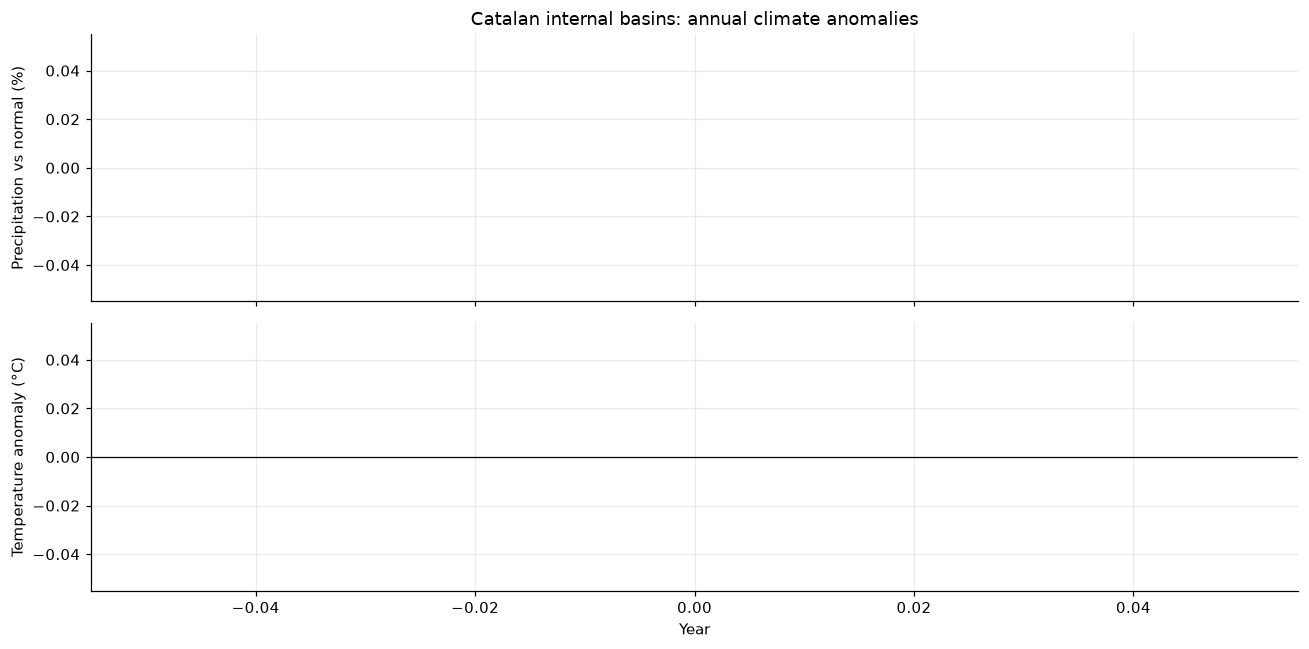


Reservoir data:
Date range: 2000-01 -> 2026-11
Minimum storage: 15.0% on 2024-02


,res
DIA,
2026-07-01,85.760176
2026-08-01,79.091558
2026-09-01,74.372090
2026-10-01,73.948907
2026-11-01,76.546840



Official drought dataset:
Dimensions: (8677, 9)
Columns: ['DATA_CANVI_ESTAT_SEQUERA', 'CODI_UNITAT_EXPLOTACI', 'UNITAT_EXPLOTACI', 'CODI_ESTAT_SEQUERA_HIDROL', 'ESTAT_SEQUERA_HIDROL_GIC', 'CODI_ESTAT_SEQUERA_PLUVIOM', 'ESTAT_SEQUERA_PLUVIOM_TRIC', 'CODI_MUNICIPI', 'MUNICIPI']


,DATA_CANVI_ESTAT_SEQUERA,CODI_UNITAT_EXPLOTACI,UNITAT_EXPLOTACI,CODI_ESTAT_SEQUERA_HIDROL,ESTAT_SEQUERA_HIDROL_GIC,CODI_ESTAT_SEQUERA_PLUVIOM,ESTAT_SEQUERA_PLUVIOM_TRIC,CODI_MUNICIPI,MUNICIPI
0,2025-05-16T00:00:00.000,3,Aqüífer Fluvià - Muga,4,NORMALITAT,1,NORMALITAT,170010,Agullana
1,2025-05-16T00:00:00.000,3,Aqüífer Fluvià - Muga,4,NORMALITAT,1,NORMALITAT,170118,"Armentera, l'"
2,2025-05-16T00:00:00.000,3,Aqüífer Fluvià - Muga,4,NORMALITAT,1,NORMALITAT,170427,Capmany
3,2025-05-16T00:00:00.000,3,Aqüífer Fluvià - Muga,4,NORMALITAT,1,NORMALITAT,170643,Espolla
4,2025-05-16T00:00:00.000,3,Aqüífer Fluvià - Muga,4,NORMALITAT,1,NORMALITAT,170773,Garriguella
5,2025-05-16T00:00:00.000,3,Aqüífer Fluvià - Muga,4,NORMALITAT,1,NORMALITAT,170865,"Jonquera, la"
6,2025-05-16T00:00:00.000,3,Aqüífer Fluvià - Muga,4,NORMALITAT,1,NORMALITAT,171002,Masarac
7,2025-05-16T00:00:00.000,3,Aqüífer Fluvià - Muga,4,NORMALITAT,1,NORMALITAT,171061,Mollet de Peralada
8,2025-05-16T00:00:00.000,3,Aqüífer Fluvià - Muga,4,NORMALITAT,1,NORMALITAT,171208,Palau-saverdera
9,2025-05-16T00:00:00.000,3,Aqüífer Fluvià - Muga,4,NORMALITAT,1,NORMALITAT,171289,Pau



Detected columns:
Date: DATA_CANVI_ESTAT_SEQUERA
Hydrological status: CODI_ESTAT_SEQUERA_HIDROL
Pluviometric status: None
Exploitation unit: None
Municipality: CODI_MUNICIPI

Date range of official drought records:
2021-01-01 00:00:00
2025-05-16 00:00:00


,DATA_CANVI_ESTAT_SEQUERA,CODI_UNITAT_EXPLOTACI,UNITAT_EXPLOTACI,CODI_ESTAT_SEQUERA_HIDROL,ESTAT_SEQUERA_HIDROL_GIC,CODI_ESTAT_SEQUERA_PLUVIOM,ESTAT_SEQUERA_PLUVIOM_TRIC,CODI_MUNICIPI,MUNICIPI
8676,2021-01-01,18,Serralada Transversal,4,NORMALITAT,1,NORMALITAT,172333,Vilobí d'Onyar
8259,2021-01-01,8,Consorci d'Aigües Tarragona,4,NORMALITAT,1,NORMALITAT,430385,Cambrils
8258,2021-01-01,8,Consorci d'Aigües Tarragona,4,NORMALITAT,1,NORMALITAT,430379,Calafell
8257,2021-01-01,8,Consorci d'Aigües Tarragona,4,NORMALITAT,1,NORMALITAT,430290,Blancafort
8256,2021-01-01,8,Consorci d'Aigües Tarragona,4,NORMALITAT,1,NORMALITAT,430249,Bellvei
8255,2021-01-01,8,Consorci d'Aigües Tarragona,4,NORMALITAT,1,NORMALITAT,430206,Banyeres del Penedès
8254,2021-01-01,8,Consorci d'Aigües Tarragona,4,NORMALITAT,1,NORMALITAT,430167,"Arboç, l'"
8253,2021-01-01,8,Consorci d'Aigües Tarragona,4,NORMALITAT,1,NORMALITAT,439060,"Ampolla, l'"
8252,2021-01-01,8,Consorci d'Aigües Tarragona,4,NORMALITAT,1,NORMALITAT,430136,"Ametlla de Mar, l'"
8251,2021-01-01,8,Consorci d'Aigües Tarragona,4,NORMALITAT,1,NORMALITAT,430120,Altafulla



Categories in CODI_ESTAT_SEQUERA_HIDROL:
CODI_ESTAT_SEQUERA_HIDROL
5      2260
6      2176
7      1864
4      1822
121     258
120     202
8        71
9        24
Name: count, dtype: int64

Dry episodes and reservoir response:


""



Number of distinct official change dates: 40


ValueError: No valid reservoir data to plot.

In [7]:
# ============================================================
# WATER ANALYSIS - CATALONIA
# From meteorological drought to reservoir depletion
# and official drought status
# ============================================================

import warnings
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False
})


# ============================================================
# 0. CONFIGURATION AND FUNCTIONS
# ============================================================

SOCRATA = (
    "https://analisi.transparenciacatalunya.cat/"
    "resource/{}.csv?$limit=1000000"
)

def load(dataset_id):
    """Download a Socrata dataset."""
    url = SOCRATA.format(dataset_id)
    return pd.read_csv(url, low_memory=False).rename(
        columns=str.upper
    )


def pick(df, *names):
    """Find the first existing column."""
    for name in names:
        if name in df.columns:
            return name
    raise KeyError(
        f"Columns {names} not found. "
        f"Available columns: {list(df.columns)}"
    )


def normalise_name(name):
    """Normalise column names for flexible matching."""
    name = unicodedata.normalize("NFKD", str(name))
    name = "".join(c for c in name if not unicodedata.combining(c))
    return re.sub(r"[^A-Z0-9]", "", name.upper())


def find_column(df, patterns):
    """Find a column matching one of the supplied patterns."""
    for pattern in patterns:
        for col in df.columns:
            if re.search(pattern, normalise_name(col)):
                return col
    return None


def months_between(a, b):
    return (b.year - a.year) * 12 + b.month - a.month


# Approximate catchment selection.
# Check that these are the intended stations for your study.
CATCHMENT = [
    "Ripollès", "Osona", "Berguedà", "Bages",
    "Garrotxa", "Selva", "Gironès", "Anoia",
    "Moianès", "Vallès Occidental", "Vallès Oriental",
    "Maresme", "Baix Llobregat", "Alt Penedès",
    "Garraf", "Barcelonès", "Alt Empordà",
    "Baix Empordà", "Pla de l'Estany", "Solsonès"
]


# ============================================================
# 1. LOAD METEOROLOGICAL DATA (XEMA)
# ============================================================

path_xema = (
    r"C:\Users\nmayo\OneDrive\Escritorio"
    r"\Máster - UB\Análisis de datos masivos"
    r"\Datasets - Agua"
    r"\Dades_meteorològiques_diàries_de_la_XEMA_20261116.csv"
)

df_xema = pd.read_csv(path_xema, low_memory=False)

print("XEMA dimensions:", df_xema.shape)
display(df_xema.head())


# Load metadata
stations = load("yqwd-vj5e")
variables = load("4fb2-n3yi")

print("Station metadata:", stations.shape)
print("Variable metadata:", variables.shape)



# ============================================================
# 2. CLEAN AND TRANSFORM METEOROLOGICAL DATA (XEMA)
# ============================================================

d = df_xema.rename(columns=str.upper).copy()

# Check available columns
print("Available columns:")
print(d.columns.tolist())

# The daily XEMA dataset already contains NOM_VARIABLE
# and VALOR, so we do not need the variable metadata dataset.

c_st = "CODI_ESTACIO"
c_dt = "DATA_LECTURA"
c_var = "NOM_VARIABLE"
c_val = "VALOR"

# Normalise variable names to facilitate matching
def clean_text(x):
    x = str(x).strip().lower()
    x = unicodedata.normalize("NFKD", x)
    return "".join(
        c for c in x
        if not unicodedata.combining(c)
    )

d["_variable"] = d[c_var].apply(clean_text)

# Inspect the actual variable names
print("\nPrecipitation-related variables:")
print(
    d.loc[
        d["_variable"].str.contains("precipit", na=False),
        c_var
    ].value_counts()
)

print("\nTemperature-related variables:")
print(
    d.loc[
        d["_variable"].str.contains("temperatura", na=False),
        c_var
    ].value_counts()
)

# Identify the variables
ppt_mask = d["_variable"].str.contains(
    "precipitacio", na=False
)

temp_mask = d["_variable"].str.contains(
    "temperatura mitjana", na=False
)

# Show selected variables
print("\nSelected precipitation variables:")
print(d.loc[ppt_mask, c_var].value_counts())

print("\nSelected temperature variables:")
print(d.loc[temp_mask, c_var].value_counts())

# Select observations
selected = d[ppt_mask | temp_mask].copy()

# Assign standard variable names
selected["var"] = np.select(
    [selected["_variable"].str.contains("precipitacio"),
     selected["_variable"].str.contains("temperatura mitjana")],
    ["ppt", "tmean"],
    default=None
)

# Convert dates and values
selected["date"] = pd.to_datetime(
    selected[c_dt],
    errors="coerce"
).dt.normalize()

selected["val"] = pd.to_numeric(
    selected[c_val],
    errors="coerce"
)

# Remove invalid observations
selected = selected.dropna(
    subset=["date", "val", c_st]
)

# Create one row per station and day
daily = (
    selected.pivot_table(
        index=[c_st, "date"],
        columns="var",
        values="val",
        aggfunc="mean"
    )
    .reset_index()
    .rename(columns={c_st: "station"})
)

daily.columns.name = None

# Ensure both variables exist
for col in ["ppt", "tmean"]:
    if col not in daily.columns:
        daily[col] = np.nan

# Remove negative precipitation values
daily.loc[daily["ppt"] < 0, "ppt"] = np.nan

print("\nDaily dataset successfully transformed")
print("Dimensions:", daily.shape)
print("Stations:", daily.station.nunique())
print("Date range:", daily.date.min(), "->", daily.date.max())

display(daily.head(10))


# ============================================================
# 3. MONTHLY DATA AND CLIMATE ANOMALIES
# ============================================================

daily["month"] = (
    daily.date.dt.to_period("M").dt.to_timestamp()
)

mon = (
    daily.groupby(["station", "month"])
    .agg(
        ppt=("ppt", "sum"),
        n_p=("ppt", "count"),
        tmean=("tmean", "mean"),
        n_t=("tmean", "count")
    )
    .reset_index()
)

# Keep approximately complete months
mon.loc[mon.n_p < 25, "ppt"] = np.nan
mon.loc[mon.n_t < 25, "tmean"] = np.nan

# Keep stations with at least 10 years of precipitation data
mon = mon[
    mon.groupby("station")["ppt"].transform("count") >= 120
].copy()

mon["cm"] = mon.month.dt.month

# Precipitation anomaly relative to the station's monthly climatology
clim_p = (
    mon.groupby(["station", "cm"])["ppt"]
    .transform("mean")
    .replace(0, np.nan)
)

mon["ppt_a"] = (mon["ppt"] / clim_p).clip(upper=5)

# Temperature anomaly in degrees Celsius
clim_t = mon.groupby(
    ["station", "cm"]
)["tmean"].transform("mean")

mon["t_a"] = mon["tmean"] - clim_t


# ============================================================
# 4. STATION METADATA AND CATCHMENT FILTER
# ============================================================

s_lat = pick(stations, "LATITUD", "LAT")
s_lon = pick(stations, "LONGITUD", "LON")
s_id = pick(stations, "CODI_ESTACIO", "CODI")

s_com = find_column(
    stations,
    [r"NOMCOMARCA", r"COMARCA"]
)

meta = stations.rename(
    columns={
        s_id: "station",
        s_lat: "lat",
        s_lon: "lon"
    }
).drop_duplicates("station").copy()

meta["lat"] = pd.to_numeric(meta["lat"], errors="coerce")
meta["lon"] = pd.to_numeric(meta["lon"], errors="coerce")

if s_com is not None:
    meta["in_catch"] = (
        meta[s_com].astype(str).str.strip().isin(CATCHMENT)
    )
else:
    raise ValueError(
        "No county column found in station metadata. "
        "Check stations.columns before continuing."
    )

mon = mon.merge(
    meta[["station", "lat", "lon", "in_catch"]],
    on="station",
    how="left"
)

print(
    "Stations used:", mon.station.nunique(),
    "| In catchment:",
    mon.loc[mon.in_catch == True, "station"].nunique()
)


# ============================================================
# 5. REGIONAL MONTHLY SERIES AND SPI-LIKE INDICES
# ============================================================

reg = (
    mon[mon.in_catch == True]
    .groupby("month")
    .agg(
        p=("ppt_a", "mean"),
        t=("t_a", "mean"),
        ns=("ppt_a", "count")
    )
    .asfreq("MS")
)

reg.loc[reg.ns < 10, ["p", "t"]] = np.nan

# Approximate standardised precipitation indices.
# These are SPI-like indices, not the conventional Gamma-based SPI.

for k in (3, 6, 12):
    rolling_p = reg["p"].rolling(
        k, min_periods=k
    ).mean()

    reg[f"spi{k}"] = (
        rolling_p - rolling_p.mean()
    ) / rolling_p.std()


# ============================================================
# 6. SPATIAL ANALYSIS: PRECIPITATION AND WARMING
# ============================================================

# Keep stations with at least 15 years of observations
yr_filtered = (
    yr.groupby("station")
    .filter(lambda g: len(g) >= 15)
)

# Calculate the linear trend independently for each station
results = []

for station, g in yr_filtered.groupby("station"):

    g = g.dropna(subset=["year", "mean"])

    if len(g) < 15:
        continue

    slope = np.polyfit(
        g["year"].to_numpy(),
        g["mean"].to_numpy(),
        1
    )[0]

    results.append({
        "station": station,
        "warming": slope * 10
    })

# Create the final DataFrame
trend = pd.DataFrame(results)

print("Temperature trends calculated:")
print(trend.shape)
display(trend.head())



# ============================================================
# 7. TEMPORAL ANALYSIS: ANNUAL CLIMATE ANOMALIES
# ============================================================

ann = (
    reg.groupby(reg.index.year)
    .agg(
        p=("p", "mean"),
        t=("t", "mean"),
        n=("p", "count")
    )
)

ann = ann[ann.n >= 11]

fig, ax = plt.subplots(
    2, 1, figsize=(12, 6), sharex=True
)

ax[0].bar(
    ann.index,
    ann.p * 100 - 100,
    color=np.where(ann.p < 1, "#d6604d", "#4393c3")
)

ax[0].set_ylabel("Precipitation vs normal (%)")

ax[1].plot(
    ann.index, ann.t,
    marker="o", color="#b2182b"
)

ax[1].axhline(0, color="k", lw=.8)
ax[1].set_ylabel("Temperature anomaly (°C)")
ax[1].set_xlabel("Year")

ax[0].set_title(
    "Catalan internal basins: annual climate anomalies"
)

plt.tight_layout()
plt.savefig("fig2_when.png", dpi=200)
plt.show()


# ============================================================
# 8. RESERVOIRS: ACA DATA
# ============================================================

res = load("gn9e-3qhr")

c_day = pick(res, "DIA", "DATA")
c_est = pick(res, "ESTACIO", "ESTACI", "EMBASSAMENT")
c_vol = pick(res, "VOLUM_EMBASSAT")
c_pct = pick(res, "PERCENTATGE_VOLUM_EMBASSAT")

res[c_day] = pd.to_datetime(
    res[c_day], errors="coerce"
).dt.normalize()

for c in (c_vol, c_pct):
    res[c] = pd.to_numeric(res[c], errors="coerce")

# Estimate capacity for each reservoir
# Exclude zero or invalid percentages
res["cap_estimated"] = np.where(
    res[c_pct] > 0,
    res[c_vol] / (res[c_pct] / 100),
    np.nan
)

capacity = (
    res.groupby(c_est)["cap_estimated"]
    .median()
)

res["cap"] = res[c_est].map(capacity)

# Daily total system storage
sysd = (
    res.groupby(c_day)
    .agg(
        vol=(c_vol, "sum"),
        cap=("cap", "sum"),
        n=(c_est, "nunique")
    )
)

# Require at least 90% of the maximum number of reservoirs
max_reservoirs = sysd["n"].max()

sysd = sysd[
    sysd["n"] >= 0.9 * max_reservoirs
].copy()

sysd["reservoir_pct"] = (
    100 * sysd["vol"] / sysd["cap"]
)

# Monthly average system storage
resm = (
    sysd["reservoir_pct"]
    .resample("MS")
    .mean()
    .rename("res")
)

print("\nReservoir data:")
print(
    f"Date range: {resm.index.min():%Y-%m} "
    f"-> {resm.index.max():%Y-%m}"
)
print(
    f"Minimum storage: {resm.min():.1f}% "
    f"on {resm.idxmin():%Y-%m}"
)

display(resm.to_frame().tail())


# ============================================================
# 9. OFFICIAL DROUGHT STATUS: ACA DATASET
# ============================================================

df_sequera = load("i5n8-43cw")

print("\nOfficial drought dataset:")
print("Dimensions:", df_sequera.shape)
print("Columns:", df_sequera.columns.tolist())

display(df_sequera.head(10))

# Identify relevant columns
date_col = find_column(
    df_sequera,
    [r"DATACANVIESTAT", r"DATACANVI", r"DATA"]
)

hydro_col = find_column(
    df_sequera,
    [r"ESTATSEQUERAHIDROLOGICA",
     r"ESTATSEQUERAHIDRO",
     r"SEQUERAHIDROLOGICA"]
)

pluvio_col = find_column(
    df_sequera,
    [r"SEQUERAPLUVIOMETRICA",
     r"CODISEQUERAPLUVIOMETRICA",
     r"PLUVIOMETRICA"]
)

unit_col = find_column(
    df_sequera,
    [r"UNITATEXPLOTACIO",
     r"NOMUNITATEXPLOTACIO"]
)

municipality_col = find_column(
    df_sequera,
    [r"NOMMUNICIPI",
     r"MUNICIPI"]
)

print("\nDetected columns:")
print("Date:", date_col)
print("Hydrological status:", hydro_col)
print("Pluviometric status:", pluvio_col)
print("Exploitation unit:", unit_col)
print("Municipality:", municipality_col)

if date_col is None:
    raise ValueError(
        "Could not identify the date column. "
        "Check the printed column names."
    )

# Convert date
df_sequera[date_col] = pd.to_datetime(
    df_sequera[date_col],
    errors="coerce",
    dayfirst=True
)

df_sequera = df_sequera.dropna(
    subset=[date_col]
).copy()

# Sort official changes chronologically
df_sequera = df_sequera.sort_values(date_col)

print("\nDate range of official drought records:")
print(df_sequera[date_col].min())
print(df_sequera[date_col].max())

display(df_sequera.head(10))

# Show actual categories; do not assume a global drought state
for col in [hydro_col, pluvio_col]:
    if col is not None:
        print(f"\nCategories in {col}:")
        print(df_sequera[col].value_counts(dropna=False))


# ============================================================
# 10. MERGE METEOROLOGICAL AND RESERVOIR SERIES
# ============================================================

ana = reg.join(resm, how="left")

# Reservoir anomaly relative to the monthly climatology
reservoir_climatology = (
    ana["res"].groupby(ana.index.month).transform("mean")
)

ana["res_anomaly"] = (
    ana["res"] - reservoir_climatology
)

ana["res_z"] = (
    ana["res_anomaly"] / ana["res"].std()
)


# ============================================================
# 11. IDENTIFY DRY EPISODES
# ============================================================

# Three consecutive months with SPI-6 <= -1
dry_condition = ana["spi6"] <= -1

run = (
    dry_condition.astype(int)
    .rolling(3, min_periods=3)
    .sum()
    .eq(3)
)

starts = [
    t - pd.DateOffset(months=2)
    for t in ana.index[
        run & ~run.shift(1, fill_value=False)
    ]
]

# Merge episodes separated by less than 540 days
onsets = []

for t in starts:
    if not onsets or (t - onsets[-1]).days > 540:
        onsets.append(t)


# ============================================================
# 12. RESPONSE TIME OF RESERVOIRS
# ============================================================

rows = []

for onset in onsets:

    window = ana.loc[
        onset:onset + pd.DateOffset(months=60),
        "res"
    ]

    row = {
        "Dry onset": onset.strftime("%Y-%m"),
        "Minimum reservoir storage (%)":
            round(window.min(), 1)
            if window.notna().any() else np.nan
    }

    for name, threshold in [
        ("Alert (<40%)", 40),
        ("Exceptionality (<25%)", 25),
        ("Emergency (<16%)", 16)
    ]:

        hit = window[window < threshold]

        row[f"Lag to {name} (months)"] = (
            months_between(onset, hit.index[0])
            if len(hit) else np.nan
        )

    rows.append(row)

episodes = pd.DataFrame(rows)

print("\nDry episodes and reservoir response:")
display(episodes)


# ============================================================
# 13. OFFICIAL DROUGHT CHANGES BY DATE
# ============================================================

# The official dataset contains territorial records.
# Here we extract change dates for plotting, without
# pretending that all territories share the same status.

official_dates = (
    df_sequera[date_col]
    .dropna()
    .drop_duplicates()
    .sort_values()
)

print(
    "\nNumber of distinct official change dates:",
    len(official_dates)
)


# ============================================================
# 14. MAIN FIGURE: CLIMATE -> RESERVOIRS -> DROUGHT
# ============================================================

valid_reservoir_dates = ana["res"].dropna()

if valid_reservoir_dates.empty:
    raise ValueError("No valid reservoir data to plot.")

x0 = (
    valid_reservoir_dates.index.min()
    - pd.DateOffset(months=24)
)

fig, ax = plt.subplots(
    2, 1,
    figsize=(13, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [1, 1.3]}
)

# Meteorological drought
ax[0].plot(
    ana.index, ana.spi6,
    label="SPI-6 (approx.)",
    color="#d6604d",
    lw=1.2
)

ax[0].plot(
    ana.index, ana.spi12,
    label="SPI-12 (approx.)",
    color="#2166ac",
    lw=1.6
)

ax[0].axhline(-1, ls="--", color="k", lw=.8)

for onset in onsets:
    ax[0].axvline(
        onset, color="#d6604d", alpha=.5
    )

ax[0].set_ylabel("Standardised precipitation")
ax[0].legend(loc="lower left")
ax[0].set_xlim(x0, ana.index.max())

ax[0].set_title(
    "Dry episodes -> reservoir depletion -> official drought changes"
)

# Reservoir storage
ax[1].plot(
    ana.index, ana.res,
    color="#08519c", lw=2,
    label="Reservoir storage"
)

# Approximate reference thresholds, not official status
for lo, hi, name, color in [
    (0, 16, "Emergency reference", "#b2182b"),
    (16, 25, "Exceptionality reference", "#ef8a62"),
    (25, 40, "Alert reference", "#fddbc7"),
    (40, 60, "Pre-alert reference", "#e0e0e0")
]:
    ax[1].axhspan(
        lo, hi, color=color, alpha=.25
    )

# Meteorological episode onsets
for onset in onsets:
    ax[1].axvline(
        onset, color="#d6604d", alpha=.5
    )

# Official change dates
for i, date in enumerate(official_dates):
    if ana.index.min() <= date <= ana.index.max():
        ax[1].axvline(
            date,
            color="black",
            linestyle=":",
            alpha=.35,
            linewidth=.8
        )

ax[1].set_ylim(0, 100)
ax[1].set_ylabel("Reservoir storage (% capacity)")
ax[1].set_xlabel("Date")

ax[1].set_title(
    "Reservoir evolution and official drought change dates"
)

plt.tight_layout()
plt.savefig("fig3_chain.png", dpi=200)
plt.show()


# ============================================================
# 15. CROSS-CORRELATION: RAINFALL AND RESERVOIRS
# ============================================================

lags = range(0, 25)

cc = pd.DataFrame({
    f"SPI-{k}": [
        ana["res_z"].corr(
            ana[f"spi{k}"].shift(l)
        )
        for l in lags
    ]
    for k in (3, 6, 12)
}, index=lags)

best = pd.DataFrame({
    "Best lag (months)": cc.idxmax(),
    "Maximum correlation": cc.max().round(3)
})

print("\nCross-correlation results:")
display(best)

ax = cc.plot(
    figsize=(9, 4),
    marker="o",
    ms=3
)

ax.set_xlabel(
    "Lag: precipitation index leads reservoirs (months)"
)

ax.set_ylabel(
    "Correlation with reservoir anomaly"
)

ax.set_title(
    "How long does a rainfall deficit take to reach reservoirs?"
)

plt.tight_layout()
plt.savefig("fig4_lag.png", dpi=200)
plt.show()


# ============================================================
# 16. EXPORT RESULTS
# ============================================================

episodes.to_csv(
    "dry_episodes_reservoir_response.csv",
    index=False
)

ana.to_csv(
    "monthly_climate_reservoir_analysis.csv"
)

df_sequera.to_csv(
    "official_drought_status_clean.csv",
    index=False
)

print("\nAnalysis completed successfully.")
print("Generated figures:")
print("- fig1_where.png")
print("- fig2_when.png")
print("- fig3_chain.png")
print("- fig4_lag.png")
print("\nGenerated CSV files:")
print("- dry_episodes_reservoir_response.csv")
print("- monthly_climate_reservoir_analysis.csv")
print("- official_drought_status_clean.csv")


In [8]:

# ============================================================
# DIAGNOSTIC: RESERVOIR DATA
# ============================================================

print("1. ANA DATAFRAME")
print("Shape:", ana.shape)
print("Columns:", ana.columns.tolist())
print("\nNon-null values:")
print(ana[["ppt", "res"]].count()
      if "ppt" in ana.columns and "res" in ana.columns
      else ana.count())

print("\nLast observations:")
display(ana.tail(10))

print("\n2. RESERVOIR-RELATED DATAFRAMES")

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        name_lower = name.lower()
        cols = [str(c).lower() for c in obj.columns]

        if (
            any(x in name_lower for x in ["aca", "res", "embass", "water"])
            or any(
                any(x in c for x in [
                    "volum", "percent", "capacitat",
                    "embass", "reservoir", "data"
                ])
                for c in cols
            )
        ):
            print(f"\n{name}: {obj.shape}")
            print("Columns:", obj.columns.tolist())
            display(obj.head(3))


1. ANA DATAFRAME
Shape: (0, 9)
Columns: ['p', 't', 'ns', 'spi3', 'spi6', 'spi12', 'res', 'res_anomaly', 'res_z']

Non-null values:
p              0
t              0
ns             0
spi3           0
spi6           0
spi12          0
res            0
res_anomaly    0
res_z          0
dtype: int64

Last observations:


,p,t,ns,spi3,spi6,spi12,res,res_anomaly,res_z
month,,,,,,,,,



2. RESERVOIR-RELATED DATAFRAMES

df_xema: (33475032, 10)
Columns: ['ID', 'CODI_ESTACIO', 'NOM_ESTACIO', 'DATA_LECTURA', 'CODI_VARIABLE', 'NOM_VARIABLE', 'VALOR', 'UNITAT', 'HORA _TU', 'Estat']


,ID,CODI_ESTACIO,NOM_ESTACIO,DATA_LECTURA,CODI_VARIABLE,NOM_VARIABLE,VALOR,UNITAT,HORA _TU,Estat
0,VK1000098801,VK,Raimat,01/09/1988,1.000,Temperatura mitjana diària,"23,3",°C,NaN,Representatiu
1,VK1002098801,VK,Raimat,01/09/1988,1.002,Temperatura mínima diària + hora,"18,3",°C,0:00,Representatiu
2,VK1100098801,VK,Raimat,01/09/1988,1.100,Humitat relativa mitjana diària,58,%,NaN,Representatiu



d: (33475032, 11)
Columns: ['ID', 'CODI_ESTACIO', 'NOM_ESTACIO', 'DATA_LECTURA', 'CODI_VARIABLE', 'NOM_VARIABLE', 'VALOR', 'UNITAT', 'HORA _TU', 'ESTAT', '_variable']


,ID,CODI_ESTACIO,NOM_ESTACIO,DATA_LECTURA,CODI_VARIABLE,NOM_VARIABLE,VALOR,UNITAT,HORA _TU,ESTAT,_variable
0,VK1000098801,VK,Raimat,01/09/1988,1.000,Temperatura mitjana diària,"23,3",°C,NaN,Representatiu,temperatura mitjana diaria
1,VK1002098801,VK,Raimat,01/09/1988,1.002,Temperatura mínima diària + hora,"18,3",°C,0:00,Representatiu,temperatura minima diaria + hora
2,VK1100098801,VK,Raimat,01/09/1988,1.100,Humitat relativa mitjana diària,58,%,NaN,Representatiu,humitat relativa mitjana diaria


... (8 outputs left out)


sysd: (9819, 4)
Columns: ['vol', 'cap', 'n', 'reservoir_pct']


,vol,cap,n,reservoir_pct
DIA,,,,
2000-01-01,368.94,696.565513,9,52.965585
2000-01-02,369.30,696.565513,9,53.017267
2000-01-03,368.77,696.565513,9,52.941180



df_sequera: (8677, 9)
Columns: ['DATA_CANVI_ESTAT_SEQUERA', 'CODI_UNITAT_EXPLOTACI', 'UNITAT_EXPLOTACI', 'CODI_ESTAT_SEQUERA_HIDROL', 'ESTAT_SEQUERA_HIDROL_GIC', 'CODI_ESTAT_SEQUERA_PLUVIOM', 'ESTAT_SEQUERA_PLUVIOM_TRIC', 'CODI_MUNICIPI', 'MUNICIPI']


,DATA_CANVI_ESTAT_SEQUERA,CODI_UNITAT_EXPLOTACI,UNITAT_EXPLOTACI,CODI_ESTAT_SEQUERA_HIDROL,ESTAT_SEQUERA_HIDROL_GIC,CODI_ESTAT_SEQUERA_PLUVIOM,ESTAT_SEQUERA_PLUVIOM_TRIC,CODI_MUNICIPI,MUNICIPI
8676,2021-01-01,18,Serralada Transversal,4,NORMALITAT,1,NORMALITAT,172333,Vilobí d'Onyar
8259,2021-01-01,8,Consorci d'Aigües Tarragona,4,NORMALITAT,1,NORMALITAT,430385,Cambrils
8258,2021-01-01,8,Consorci d'Aigües Tarragona,4,NORMALITAT,1,NORMALITAT,430379,Calafell
